<a href="https://colab.research.google.com/github/abrarjahinzihan/Student-Grade-Prediction/blob/main/Student_Grade_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 Student Grade Prediction
**Goal:** Predict students' final grade (`G3`, scale 0–20) from academic records, attendance, study habits, parental education and previous marks (`G1`, `G2`), then flag students who may need extra academic support.

**Models:** Linear Regression · Ridge Regression · Decision Tree Regressor  
**Metrics:** R² and RMSE  
**Dataset:** UCI *Student Performance* (Math: 395 students, Portuguese: 649 students)

**How to run:** `Runtime → Run all`, then upload your `studentperformance.zip` when prompted (the nested `student.zip` is handled automatically).

## 1. Setup

In [ ]:
import os, zipfile, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
PASS_MARK = 10   # G3 < 10 is treated as 'at risk' (fail) in the Portuguese grading system

## 2. Upload & extract the dataset

In [ ]:
# Upload the zip in Colab (skipped automatically if the CSVs already exist, e.g. when running locally)
DATA_DIR = "student_data"
os.makedirs(DATA_DIR, exist_ok=True)

def extract_all(zip_path, out_dir):
    """Extract a zip and any zips nested inside it."""
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    for inner in glob.glob(os.path.join(out_dir, "**", "*.zip"), recursive=True):
        if os.path.basename(inner).startswith("."):
            continue
        try:
            extract_all(inner, os.path.join(out_dir, os.path.splitext(os.path.basename(inner))[0]))
        except zipfile.BadZipFile:
            pass

if not glob.glob(os.path.join(DATA_DIR, "**", "student-mat.csv"), recursive=True):
    try:
        from google.colab import files
        print("Please upload your zip file (studentperformance.zip)...")
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith(".zip"):
                extract_all(name, DATA_DIR)
    except ImportError:
        local = glob.glob("*.zip")
        assert local, "Put the zip file next to this notebook."
        extract_all(local[0], DATA_DIR)

MAT = glob.glob(os.path.join(DATA_DIR, "**", "student-mat.csv"), recursive=True)[0]
POR = glob.glob(os.path.join(DATA_DIR, "**", "student-por.csv"), recursive=True)[0]
print("Found:", MAT, "|", POR)

Please upload your zip file (studentperformance.zip)...


Saving student+performance.zip to student+performance.zip
Found: student_data/student/student-mat.csv | student_data/student/student-por.csv


## 3. Load data

In [ ]:
math = pd.read_csv(MAT, sep=";")
port = pd.read_csv(POR, sep=";")
print("Math      :", math.shape)
print("Portuguese:", port.shape)
print("Missing values  -> Math:", math.isna().sum().sum(), "| Portuguese:", port.isna().sum().sum())
print("Duplicate rows  -> Math:", math.duplicated().sum(), "| Portuguese:", port.duplicated().sum())
math.head()

Math      : (395, 33)
Portuguese: (649, 33)
Missing values  -> Math: 0 | Portuguese: 0
Duplicate rows  -> Math: 0 | Portuguese: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 4. Exploratory Data Analysis

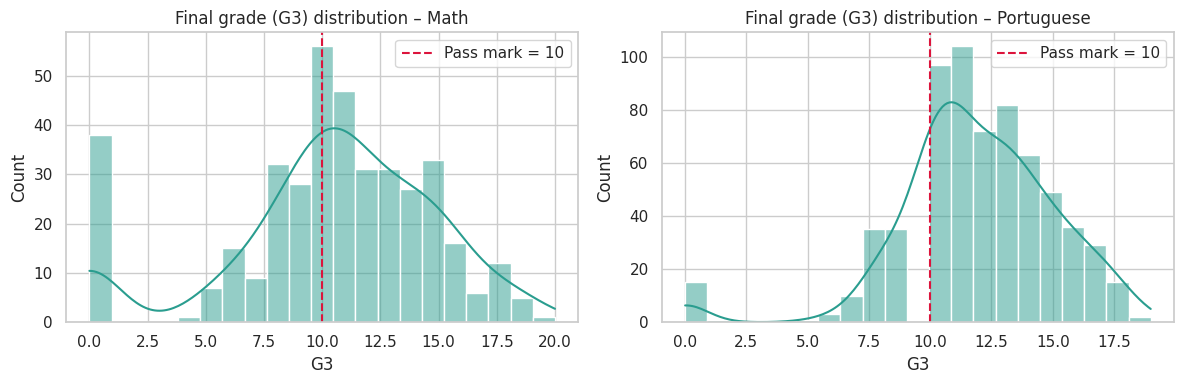

Math: mean G3 = 10.42, at-risk (G3<10) = 32.9%, students with G3 = 0: 38
Portuguese: mean G3 = 11.91, at-risk (G3<10) = 15.4%, students with G3 = 0: 15


In [ ]:
datasets = {"Math": math, "Portuguese": port}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, df) in zip(axes, datasets.items()):
    sns.histplot(df["G3"], bins=21, kde=True, ax=ax, color="#2a9d8f")
    ax.axvline(PASS_MARK, color="crimson", ls="--", label=f"Pass mark = {PASS_MARK}")
    ax.set_title(f"Final grade (G3) distribution – {name}")
    ax.legend()
plt.tight_layout(); plt.show()

for name, df in datasets.items():
    print(f"{name}: mean G3 = {df.G3.mean():.2f}, at-risk (G3<{PASS_MARK}) = {(df.G3<PASS_MARK).mean():.1%}, "
          f"students with G3 = 0: {(df.G3==0).sum()}")

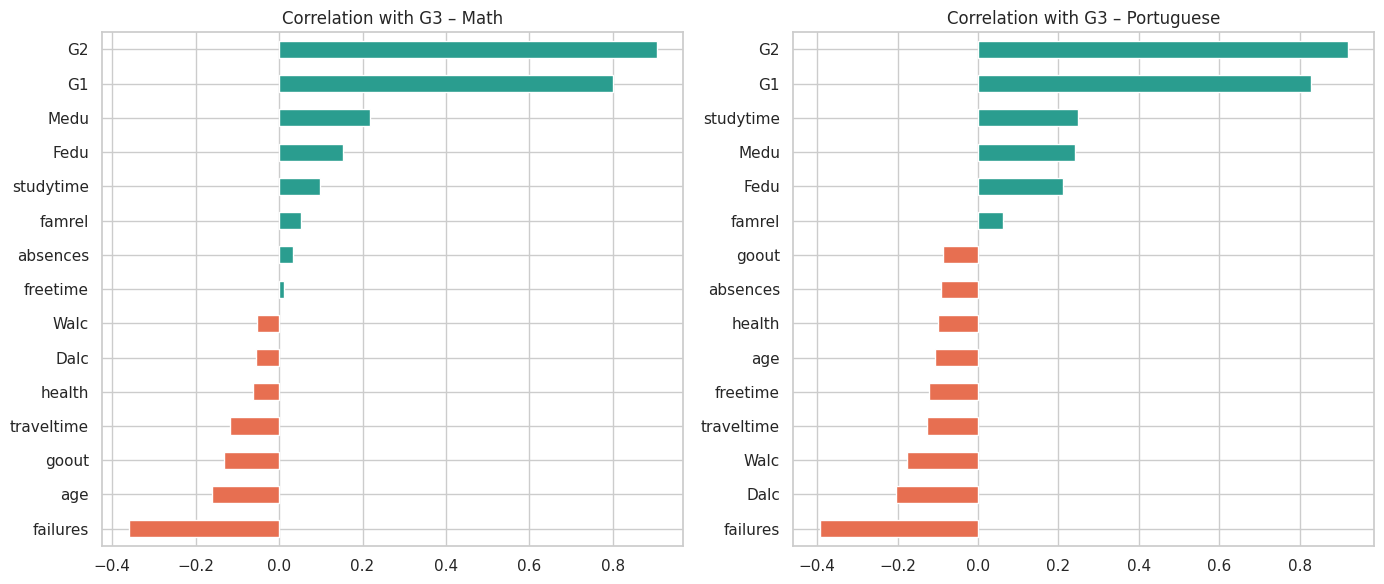

In [ ]:
# Correlation of numeric features with the final grade
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, df) in zip(axes, datasets.items()):
    corr = df.select_dtypes("number").corr()["G3"].drop("G3").sort_values()
    colors = ["#e76f51" if v < 0 else "#2a9d8f" for v in corr]
    corr.plot.barh(ax=ax, color=colors)
    ax.set_title(f"Correlation with G3 – {name}")
plt.tight_layout(); plt.show()

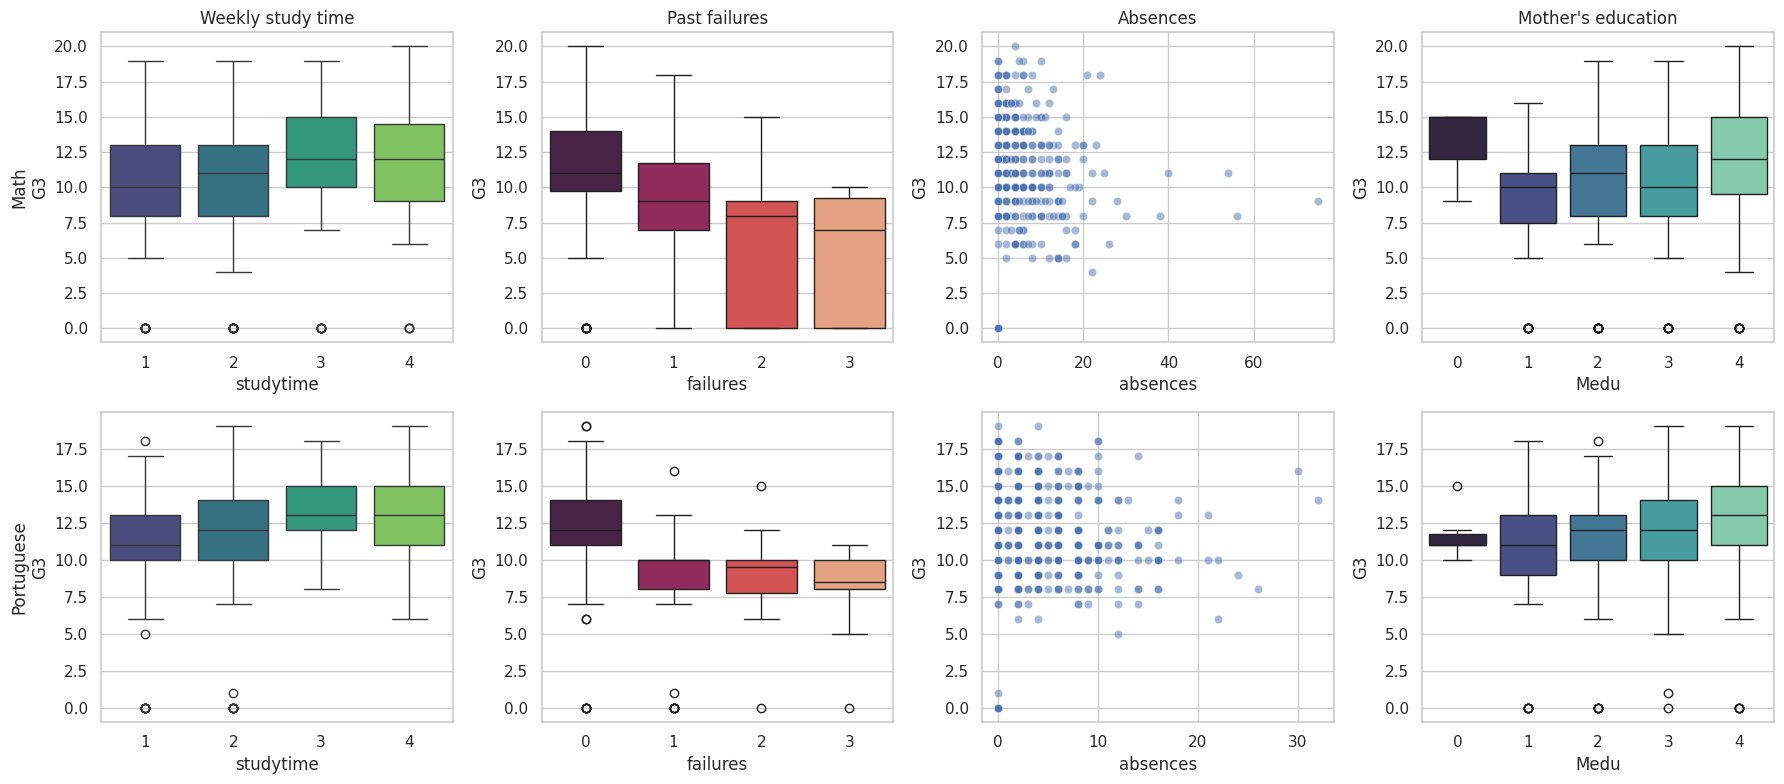

In [ ]:
# Key drivers: study time, past failures, absences, parental education
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for r, (name, df) in enumerate(datasets.items()):
    sns.boxplot(data=df, x="studytime", y="G3", ax=axes[r, 0], palette="viridis")
    sns.boxplot(data=df, x="failures", y="G3", ax=axes[r, 1], palette="rocket")
    sns.scatterplot(data=df, x="absences", y="G3", ax=axes[r, 2], alpha=.5)
    sns.boxplot(data=df, x="Medu", y="G3", ax=axes[r, 3], palette="mako")
    axes[r, 0].set_ylabel(f"{name}\nG3")
axes[0,0].set_title("Weekly study time"); axes[0,1].set_title("Past failures")
axes[0,2].set_title("Absences");          axes[0,3].set_title("Mother's education")
plt.tight_layout(); plt.show()

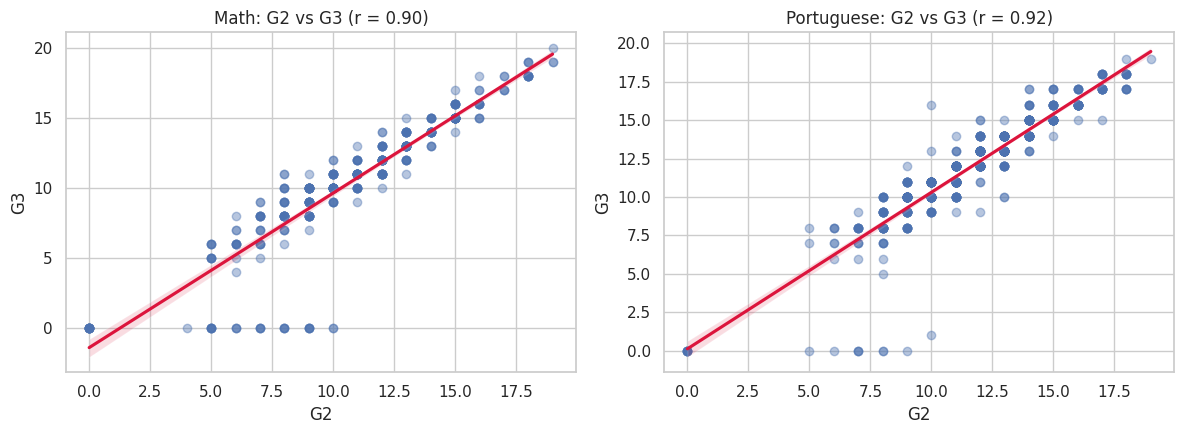

In [ ]:
# How strongly do previous marks predict the final mark?
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, df) in zip(axes, datasets.items()):
    sns.regplot(data=df, x="G2", y="G3", ax=ax, scatter_kws={"alpha": .4}, line_kws={"color": "crimson"})
    ax.set_title(f"{name}: G2 vs G3 (r = {df.G2.corr(df.G3):.2f})")
plt.tight_layout(); plt.show()

## 5. Preprocessing & modelling pipeline
- Categorical features → one-hot encoding; numeric features → standard scaling (important for Ridge).
- 80/20 train/test split, **same split for all models**.
- Hyper-parameters (Ridge `alpha`, Tree depth/leaf size) tuned with 5-fold cross-validation on the **training set only**.

We evaluate **two scenarios** for each subject:
1. **With previous marks** (`G1`, `G2` included) – the most accurate predictor.
2. **Without previous marks** – an *early-warning* model that relies only on attendance, study hours, parental education, etc.

In [ ]:
def build_preprocessor(X):
    cat = X.select_dtypes(include="object").columns.tolist()
    num = X.select_dtypes(exclude="object").columns.tolist()
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ])

def rmse(y, p): return np.sqrt(mean_squared_error(y, p))

def get_models(X_train):
    pre = build_preprocessor(X_train)
    cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
    return {
        "Linear Regression": Pipeline([("pre", pre), ("m", LinearRegression())]),
        "Ridge": GridSearchCV(
            Pipeline([("pre", pre), ("m", Ridge())]),
            {"m__alpha": np.logspace(-2, 3, 30)}, cv=cv, scoring="neg_root_mean_squared_error"),
        "Decision Tree": GridSearchCV(
            Pipeline([("pre", pre), ("m", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
            {"m__max_depth": [2, 3, 4, 5, 6, 8, None],
             "m__min_samples_leaf": [1, 3, 5, 10, 20],
             "m__min_samples_split": [2, 5, 10]},
            cv=cv, scoring="neg_root_mean_squared_error"),
    }

def run_experiment(df, use_previous_marks=True):
    X = df.drop(columns=["G3"])
    if not use_previous_marks:
        X = X.drop(columns=["G1", "G2"])
    y = df["G3"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

    rows, fitted, preds = [], {}, {}
    for name, model in get_models(X_tr).items():
        model.fit(X_tr, y_tr)
        p_tr, p_te = model.predict(X_tr), np.clip(model.predict(X_te), 0, 20)
        best = model.best_params_ if hasattr(model, "best_params_") else "-"
        rows.append({"Model": name,
                     "Train R²": r2_score(y_tr, p_tr), "Test R²": r2_score(y_te, p_te),
                     "Test RMSE": rmse(y_te, p_te), "Test MAE": mean_absolute_error(y_te, p_te),
                     "Best params": best})
        fitted[name], preds[name] = model, p_te
    res = pd.DataFrame(rows).set_index("Model")
    return res, fitted, preds, (X_tr, X_te, y_tr, y_te)

## 6. Train & evaluate all models

In [ ]:
results, store = {}, {}
for subject, df in datasets.items():
    for with_prev in (True, False):
        tag = f"{subject} | {'with G1,G2' if with_prev else 'without G1,G2'}"
        res, fitted, preds, split = run_experiment(df, with_prev)
        results[tag], store[tag] = res, (fitted, preds, split)
        print("="*100); print(tag); print("="*100)
        display(res.round(3))

Math | with G1,G2


,Train R²,Test R²,Test RMSE,Test MAE,Best params
Model,,,,,
Linear Regression,0.866,0.730,2.351,1.598,-
Ridge,0.863,0.746,2.284,1.523,{'m__alpha': 12.689610031679234}
Decision Tree,0.945,0.687,2.532,1.420,"{'m__max_depth': 5, 'm__min_samples_leaf': 3, ..."


Math | without G1,G2


,Train R²,Test R²,Test RMSE,Test MAE,Best params
Model,,,,,
Linear Regression,0.289,0.141,4.196,3.395,-
Ridge,0.219,0.151,4.173,3.378,{'m__alpha': 137.3823795883264}
Decision Tree,0.289,0.062,4.386,3.450,"{'m__max_depth': 2, 'm__min_samples_leaf': 1, ..."


Portuguese | with G1,G2


,Train R²,Test R²,Test RMSE,Test MAE,Best params
Model,,,,,
Linear Regression,0.858,0.849,1.215,0.765,-
Ridge,0.857,0.850,1.209,0.759,{'m__alpha': 12.689610031679234}
Decision Tree,0.832,0.802,1.389,0.791,"{'m__max_depth': 3, 'm__min_samples_leaf': 3, ..."


Portuguese | without G1,G2


,Train R²,Test R²,Test RMSE,Test MAE,Best params
Model,,,,,
Linear Regression,0.387,0.160,2.862,2.156,-
Ridge,0.374,0.200,2.793,2.068,{'m__alpha': 28.072162039411786}
Decision Tree,0.427,0.097,2.967,2.280,"{'m__max_depth': 5, 'm__min_samples_leaf': 10,..."


Test R²  Test RMSE  Test MAE
Experiment                 Model                                          
Math | with G1,G2          Linear Regression    0.730      2.351     1.598
                           Ridge                0.746      2.284     1.523
                           Decision Tree        0.687      2.532     1.420
Math | without G1,G2       Linear Regression    0.141      4.196     3.395
                           Ridge                0.151      4.173     3.378
                           Decision Tree        0.062      4.386     3.450
Portuguese | with G1,G2    Linear Regression    0.849      1.215     0.765
                           Ridge                0.850      1.209     0.759
                           Decision Tree        0.802      1.389     0.791
Portuguese | without G1,G2 Linear Regression    0.160      2.862     2.156
                           Ridge                0.200      2.793     2.068
                           Decision Tree        0.097      2.967     2.280

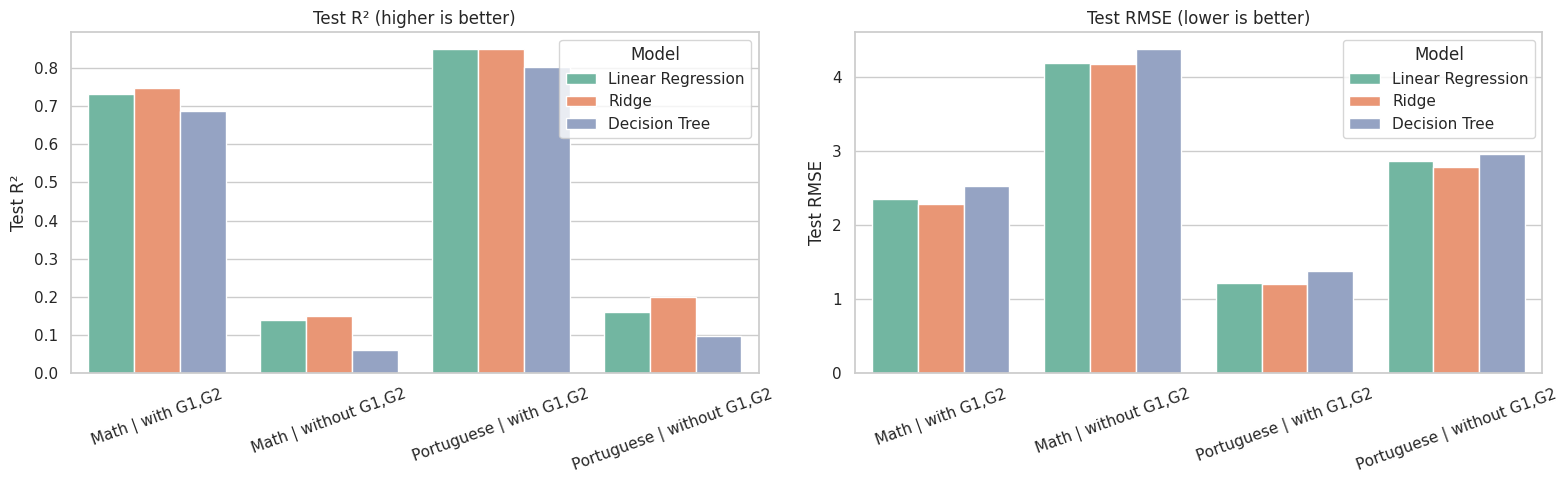

In [ ]:
# Summary table of every experiment
summary = pd.concat({k: v[["Test R²", "Test RMSE", "Test MAE"]] for k, v in results.items()}).round(3)
summary.index.names = ["Experiment", "Model"]
display(summary)

# Grouped bar charts: R² and RMSE
flat = summary.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=flat, x="Experiment", y="Test R²", hue="Model", ax=axes[0], palette="Set2")
sns.barplot(data=flat, x="Experiment", y="Test RMSE", hue="Model", ax=axes[1], palette="Set2")
for ax, t in zip(axes, ["Test R² (higher is better)", "Test RMSE (lower is better)"]):
    ax.set_title(t); ax.tick_params(axis="x", rotation=20); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 7. Predicted vs actual grades

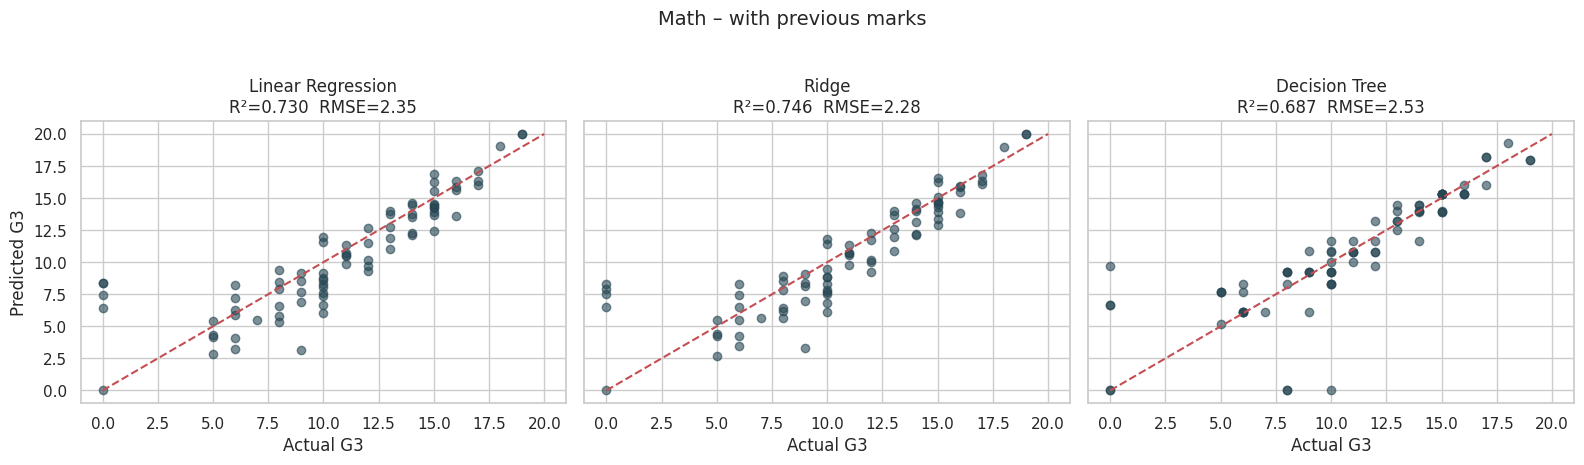

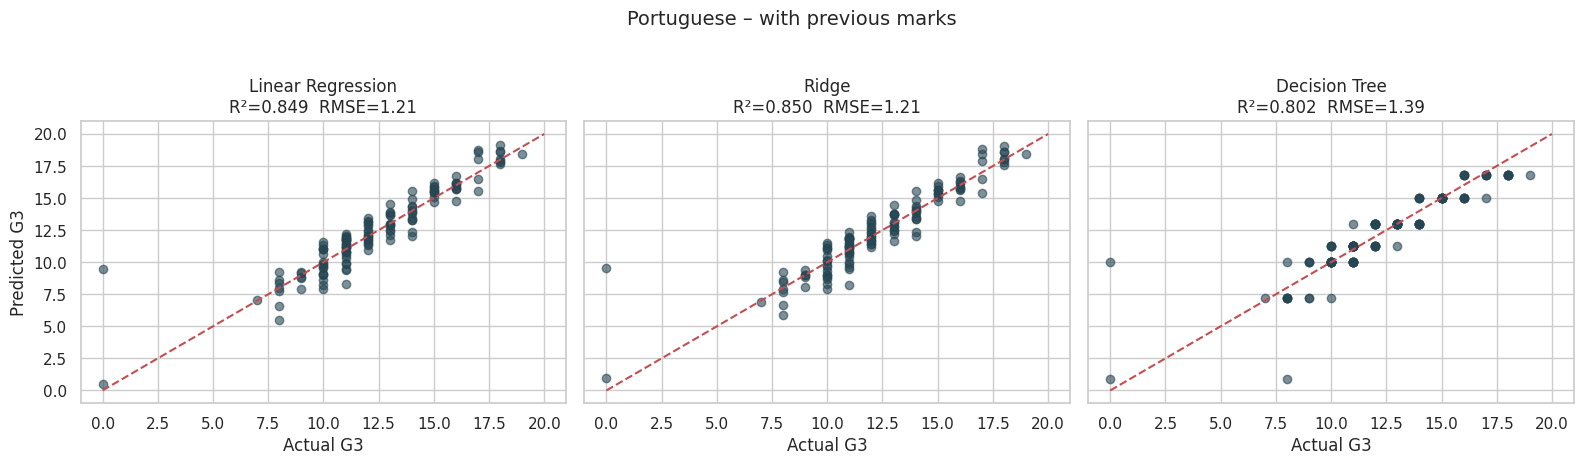

In [ ]:
for subject in datasets:
    tag = f"{subject} | with G1,G2"
    fitted, preds, (X_tr, X_te, y_tr, y_te) = store[tag]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
    for ax, (name, p) in zip(axes, preds.items()):
        ax.scatter(y_te, p, alpha=.6, color="#264653")
        ax.plot([0, 20], [0, 20], "r--")
        ax.set_title(f"{name}\nR²={r2_score(y_te, p):.3f}  RMSE={rmse(y_te, p):.2f}")
        ax.set_xlabel("Actual G3")
    axes[0].set_ylabel("Predicted G3")
    fig.suptitle(f"{subject} – with previous marks", y=1.03, fontsize=14)
    plt.tight_layout(); plt.show()

## 8. Which factors matter most?

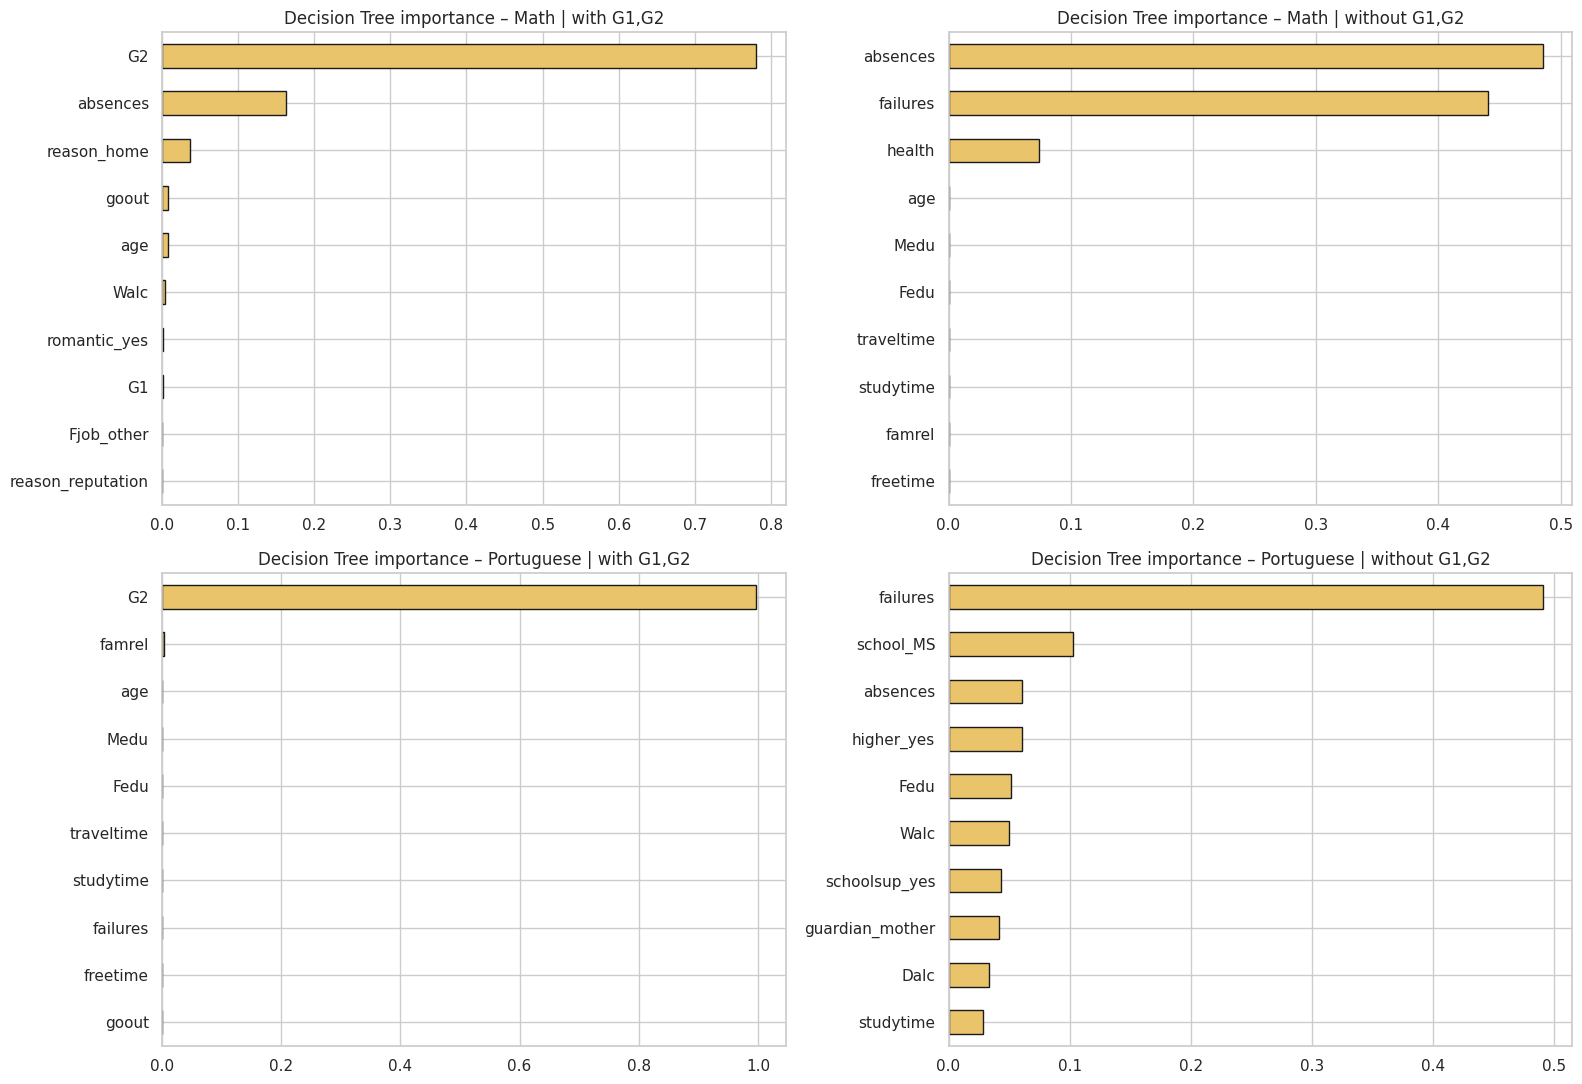

In [ ]:
def feature_names(model):
    best = model.best_estimator_ if hasattr(model, "best_estimator_") else model
    return best.named_steps["pre"].get_feature_names_out(), best.named_steps["m"]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for r, subject in enumerate(datasets):
    for c, with_prev in enumerate((True, False)):
        tag = f"{subject} | {'with G1,G2' if with_prev else 'without G1,G2'}"
        names, tree = feature_names(store[tag][0]["Decision Tree"])
        imp = pd.Series(tree.feature_importances_, index=[n.split("__")[1] for n in names]).nlargest(10)[::-1]
        imp.plot.barh(ax=axes[r, c], color="#e9c46a", edgecolor="k")
        axes[r, c].set_title(f"Decision Tree importance – {tag}")
plt.tight_layout(); plt.show()

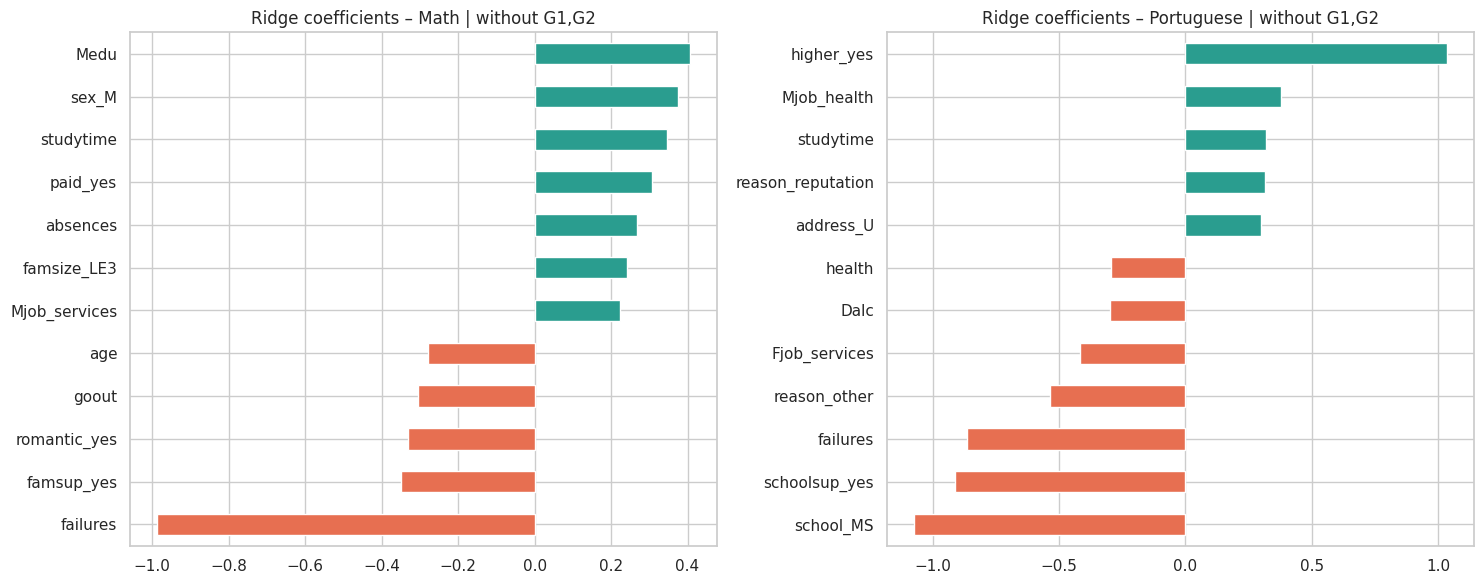

In [ ]:
# Ridge coefficients (standardised features -> directly comparable), without G1/G2
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, subject in zip(axes, datasets):
    tag = f"{subject} | without G1,G2"
    names, ridge = feature_names(store[tag][0]["Ridge"])
    coef = pd.Series(ridge.coef_, index=[n.split("__")[1] for n in names])
    top = coef.reindex(coef.abs().nlargest(12).index).sort_values()
    top.plot.barh(ax=ax, color=["#e76f51" if v < 0 else "#2a9d8f" for v in top])
    ax.set_title(f"Ridge coefficients – {tag}")
plt.tight_layout(); plt.show()

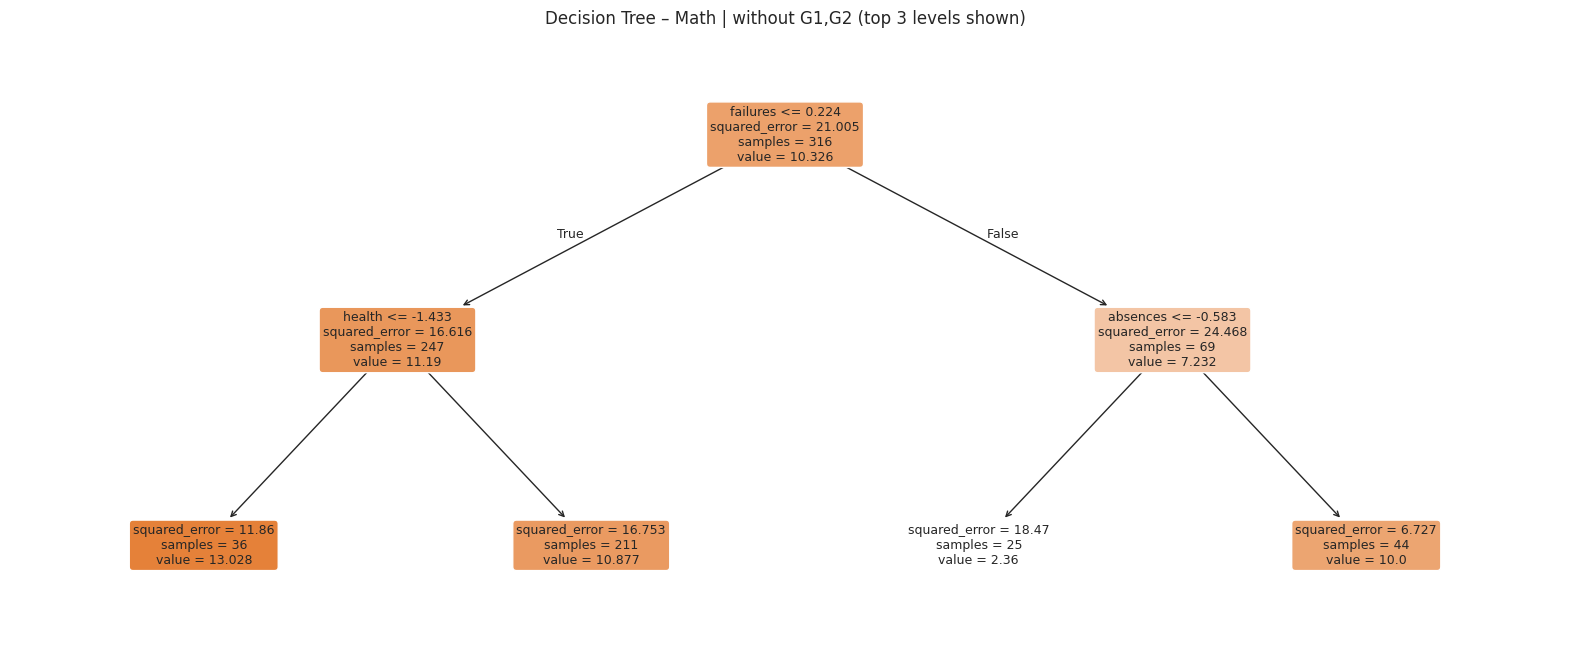

In [ ]:
# Visualise the (tuned) decision tree for Math, early-warning scenario
tag = "Math | without G1,G2"
best_tree_pipe = store[tag][0]["Decision Tree"].best_estimator_
names = [n.split("__")[1] for n in best_tree_pipe.named_steps["pre"].get_feature_names_out()]
plt.figure(figsize=(20, 8))
plot_tree(best_tree_pipe.named_steps["m"], feature_names=names, filled=True, rounded=True,
          max_depth=3, fontsize=9)
plt.title(f"Decision Tree – {tag} (top 3 levels shown)")
plt.show()

## 9. Robustness check: 5-fold cross-validation on the full data

In [ ]:
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for subject, df in datasets.items():
    for with_prev in (True, False):
        tag = f"{subject} | {'with G1,G2' if with_prev else 'without G1,G2'}"
        X = df.drop(columns=["G3"] + ([] if with_prev else ["G1", "G2"])); y = df["G3"]
        for name, model in store[tag][0].items():
            est = model.best_estimator_ if hasattr(model, "best_estimator_") else model
            r2 = cross_val_score(est, X, y, cv=cv, scoring="r2")
            rm = -cross_val_score(est, X, y, cv=cv, scoring="neg_root_mean_squared_error")
            rows.append([tag, name, r2.mean(), r2.std(), rm.mean()])
cvdf = pd.DataFrame(rows, columns=["Experiment", "Model", "CV R² mean", "CV R² std", "CV RMSE mean"]).round(3)
display(cvdf)

,Experiment,Model,CV R² mean,CV R² std,CV RMSE mean
0,"Math | with G1,G2",Linear Regression,0.792,0.042,2.057
1,"Math | with G1,G2",Ridge,0.801,0.037,2.013
2,"Math | with G1,G2",Decision Tree,0.805,0.094,1.932
3,"Math | without G1,G2",Linear Regression,0.026,0.151,4.454
4,"Math | without G1,G2",Ridge,0.128,0.037,4.244
5,"Math | without G1,G2",Decision Tree,0.207,0.097,4.035
6,"Portuguese | with G1,G2",Linear Regression,0.836,0.034,1.297
7,"Portuguese | with G1,G2",Ridge,0.839,0.036,1.284
8,"Portuguese | with G1,G2",Decision Tree,0.825,0.037,1.339
9,"Portuguese | without G1,G2",Linear Regression,0.246,0.086,2.753


## 10. Identify students who need additional support
A student is flagged **at risk** when the predicted final grade is below the pass mark (10). We use the **early-warning model (no G1/G2)** — it can be used *before* any period grades exist — and also show the model that uses previous marks.

Because we want to avoid *missing* struggling students, we also flag anyone predicted within a small **safety margin** of the pass mark.

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

MARGIN = 1.0   # flag students predicted below PASS_MARK + MARGIN
rows = []
for subject in datasets:
    for with_prev in (True, False):
        tag = f"{subject} | {'with G1,G2' if with_prev else 'without G1,G2'}"
        fitted, preds, (X_tr, X_te, y_tr, y_te) = store[tag]
        best_name = results[tag]["Test RMSE"].idxmin()
        p = preds[best_name]
        actual = (y_te < PASS_MARK).astype(int)
        for label, thr in [("strict", PASS_MARK), (f"margin +{MARGIN}", PASS_MARK + MARGIN)]:
            flag = (p < thr).astype(int)
            rows.append([tag, best_name, label, int(actual.sum()), int(flag.sum()),
                         precision_score(actual, flag, zero_division=0),
                         recall_score(actual, flag), f1_score(actual, flag)])
risk = pd.DataFrame(rows, columns=["Experiment", "Best model", "Rule", "Actual at-risk",
                                   "Flagged", "Precision", "Recall", "F1"]).round(3)
display(risk)

,Experiment,Best model,Rule,Actual at-risk,Flagged,Precision,Recall,F1
0,"Math | with G1,G2",Ridge,strict,27,38,0.711,1.000,0.831
1,"Math | with G1,G2",Ridge,margin +1.0,27,44,0.614,1.000,0.761
2,"Math | without G1,G2",Ridge,strict,27,24,0.542,0.481,0.510
3,"Math | without G1,G2",Ridge,margin +1.0,27,48,0.438,0.778,0.560
4,"Portuguese | with G1,G2",Ridge,strict,15,29,0.517,1.000,0.682
5,"Portuguese | with G1,G2",Ridge,margin +1.0,15,38,0.395,1.000,0.566
6,"Portuguese | without G1,G2",Ridge,strict,15,12,0.417,0.333,0.370
7,"Portuguese | without G1,G2",Ridge,margin +1.0,15,30,0.300,0.600,0.400


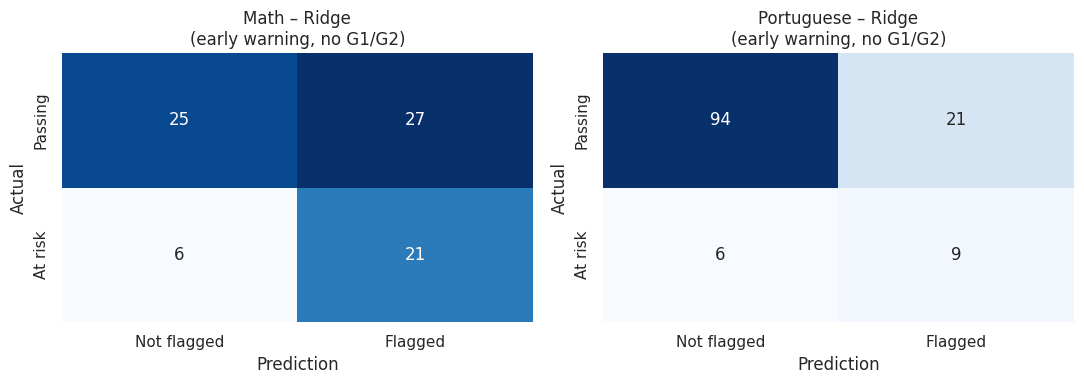

In [ ]:
# Confusion matrices for the early-warning model (with safety margin)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, subject in zip(axes, datasets):
    tag = f"{subject} | without G1,G2"
    fitted, preds, (X_tr, X_te, y_tr, y_te) = store[tag]
    best_name = results[tag]["Test RMSE"].idxmin()
    cm = confusion_matrix((y_te < PASS_MARK).astype(int), (preds[best_name] < PASS_MARK + MARGIN).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not flagged", "Flagged"], yticklabels=["Passing", "At risk"])
    ax.set_title(f"{subject} – {best_name}\n(early warning, no G1/G2)")
    ax.set_xlabel("Prediction"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [ ]:
# Final support list: main flag from the best model WITH previous marks (most accurate),
# plus an early-warning flag from the model WITHOUT G1/G2 (usable before any grades exist).
support_frames = []
for subject, df in datasets.items():
    t_full, t_early = f"{subject} | with G1,G2", f"{subject} | without G1,G2"
    m_full  = store[t_full][0][results[t_full]["Test RMSE"].idxmin()]
    m_early = store[t_early][0][results[t_early]["Test RMSE"].idxmin()]
    out = df[["school", "sex", "age", "studytime", "failures", "absences", "G1", "G2", "G3"]].copy()
    out["Subject"] = subject
    out["Predicted_G3"] = np.clip(m_full.predict(df.drop(columns=["G3"])), 0, 20).round(1)
    out["Needs_Support"] = out["Predicted_G3"] < PASS_MARK
    out["EarlyWarning_G3"] = np.clip(m_early.predict(df.drop(columns=["G3", "G1", "G2"])), 0, 20).round(1)
    out["EarlyWarning_Flag"] = out["EarlyWarning_G3"] < PASS_MARK + MARGIN
    support_frames.append(out)
support = pd.concat(support_frames).sort_values("Predicted_G3")
print("Students flagged for additional support (predicted G3 < pass mark):")
print(support.groupby("Subject")["Needs_Support"].agg(["sum", "count"]).rename(columns={"sum": "Flagged", "count": "Total"}))
print("(Predictions here include students the model was trained on, so treat the counts as indicative;")
print(" the held-out precision/recall table above is the honest accuracy estimate.)")
display(support[support.Needs_Support].head(15))

support.to_csv("students_support_list.csv", index=False)
print("\nSaved -> students_support_list.csv")

Students flagged for additional support (predicted G3 < pass mark):
            Flagged  Total
Subject                   
Math            184    395
Portuguese      162    649
(Predictions here include students the model was trained on, so treat the counts as indicative;
 the held-out precision/recall table above is the honest accuracy estimate.)


,school,sex,age,studytime,failures,absences,G1,G2,G3,Subject,Predicted_G3,Needs_Support,EarlyWarning_G3,EarlyWarning_Flag
153,GP,M,19,1,3,0,5,0,0,Math,0.0,True,5.4,True
137,GP,F,16,1,2,0,4,0,0,Math,0.0,True,7.1,True
144,GP,M,17,1,3,0,5,0,0,Math,0.0,True,5.4,True
162,GP,M,16,1,1,0,7,0,0,Math,0.0,True,8.1,True
244,GP,F,18,3,0,0,7,0,0,Math,0.0,True,9.8,True
269,GP,F,18,2,0,0,6,0,0,Math,0.0,True,8.5,True
332,GP,F,18,2,0,0,7,0,0,Math,0.0,True,10.4,True
130,GP,F,15,3,2,0,12,0,0,Math,0.2,True,8.2,True
605,MS,F,19,1,1,0,5,0,0,Portuguese,0.4,True,7.7,True
567,MS,M,18,1,1,0,4,0,0,Portuguese,0.5,True,8.5,True



Saved -> students_support_list.csv


## 11. Predict for a single new student (demo)

In [ ]:
# Example: a new Math student (early-warning model, no previous marks)
new_student = pd.DataFrame([{
    "school": "GP", "sex": "F", "age": 17, "address": "U", "famsize": "GT3", "Pstatus": "T",
    "Medu": 3, "Fedu": 2, "Mjob": "services", "Fjob": "other", "reason": "course", "guardian": "mother",
    "traveltime": 1, "studytime": 2, "failures": 1, "schoolsup": "no", "famsup": "yes", "paid": "no",
    "activities": "yes", "nursery": "yes", "higher": "yes", "internet": "yes", "romantic": "no",
    "famrel": 4, "freetime": 3, "goout": 3, "Dalc": 1, "Walc": 2, "health": 4, "absences": 6}])

tag = "Math | without G1,G2"
best_name = results[tag]["Test RMSE"].idxmin()
pred = float(np.clip(store[tag][0][best_name].predict(new_student)[0], 0, 20))
print(f"Model used     : {best_name}")
print(f"Predicted G3   : {pred:.1f} / 20")
print("Recommendation :", "⚠️ Provide additional academic support" if pred < PASS_MARK + MARGIN else "✅ On track")

Model used     : Ridge
Predicted G3   : 9.3 / 20
Recommendation : ⚠️ Provide additional academic support
